In [1]:
from dataclasses import dataclass, field
from typing import Optional, Sequence

import numpy as np
import pandas as pd

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import XGate
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

from src.linear_tag import (
    int_to_bits,
    bits_to_int,
    gf2_rank,
    tag_value,
    Transcript,
    KeyedLinearTagModel
)


# Keyed Linear-Tag Construction

## 1. Experimental setup

This notebook studies the keyed linear-tag construction of
Section IV of the reference paper.

A model consists of `nu` independently keyed circuit blocks.
Each block operates on the same computational-basis input
and produces one measurement transcript.

The paper-exact construction uses:

$$
m=n,\qquad 1\le s\le n,
$$

with XOR permutations

$$
\pi_t(x)=x\oplus t
$$

and secret matrices

$$
B_j\in\mathbb F_2^{s\times n},
\qquad j=1,\ldots,\nu.
$$

All model parameters, key matrices, and permutation choices
are fixed at initialization.

We first inspect the model and its logical resources, then
study its quantum circuits and classical transcript sampler.


![Block diagram](./img/blocchi.png)


In [2]:
from IPython.display import display
# ============================================================
# EXPERIMENT PARAMETERS
# ============================================================

N = 3
M = N
S = 2
NU = 2

SEED = 42
X = 0b101 #explicit bit format

# None: generate independent pseudorandom binary matrices.
KEY_MATRICES = None

# To use explicit keys instead, uncomment:
#
# KEY_MATRICES = [
#     np.array([
#         [1, 0, 1],
#         [0, 1, 0],
#     ], dtype=np.uint8),
#
#     np.array([
#         [0, 0, 1],
#         [1, 1, 0],
#     ], dtype=np.uint8),
# ]

# None: use the exact XOR permutation family of the paper.
MASKS = None

# ============================================================
# INITIALIZATION
# ============================================================

model = KeyedLinearTagModel(
    n=N,
    m=M,
    s=S,
    nu=NU,
    masks=MASKS,
    key_matrices=KEY_MATRICES,
    seed=SEED,
)

# Full information is printed immediately after initialization.
model.describe(show_keys=True)

print(f"\nInput x = {X:0{N}b}")

# Inspect the logical resource counts from Table I.
display(model.resource_table())

KEYED LINEAR-TAG MODEL
Paper-exact construction : True
System qubits (n)        : 3
Index qubits (m)         : 3
Tag qubits (s)           : 2
Keyed blocks (nu)        : 2
Permutation labels (K)  : 8
Qubits per block         : 8
Seed                     : 42
Key source               : Pseudorandom
Permutation family       : pi_t(x) = x XOR t

Secret key B_1:
[[1 0 1]
 [0 1 1]]
rank(B_1) = 2

Secret key B_2:
[[1 1 1]
 [1 0 0]]
rank(B_2) = 2

DECODING INFORMATION
rank(A)                  : 3
Full column rank         : True
Random-key failure bound : 0.4375
Random-key inversion bound: 0.7916666666666666

TOTAL LOGICAL RESOURCES
executions               : 2
qubits                   : 8
hadamards                : 12
cnot                     : 14
expected_cnot            : 12.0
logical_two_qubit_depth  : 7
measured_bits            : 16
secret_key_bits          : 12
classical_decoding       : O(nu * s * n^2)

Input x = 101


,Block 1,Block 2,Total
Resource,,,
Executions,1.0,1.0,2
Qubits,8.0,8.0,8
Hadamard gates,6.0,6.0,12
CNOT gates,7.0,7.0,14
Expected CNOT gates,6.0,6.0,12.0
Logical two-qubit depth,3.0,4.0,7
Measured bits,8.0,8.0,16
Secret-key bits,6.0,6.0,12
Classical decoding,NaN,NaN,O(nu * s * n^2)


In [3]:
print("Total CNOTs:", model.resources["total"]["cnot"])
print("Total executions:", model.resources["total"]["executions"])
print("Rank(A):", model.resources["rank_A"])
print("Full column rank:", model.resources["full_column_rank"])

Total CNOTs: 14
Total executions: 2
Rank(A): 3
Full column rank: True


XOR permutation family:


,Label t,Mask,Output
0,000,000,101
1,001,001,100
2,010,010,111
3,011,011,110
4,100,100,001
5,101,101,000
6,110,110,011
7,111,111,010



Block 1/2
Key matrix B_1:
[[1 0 1]
 [0 1 1]]


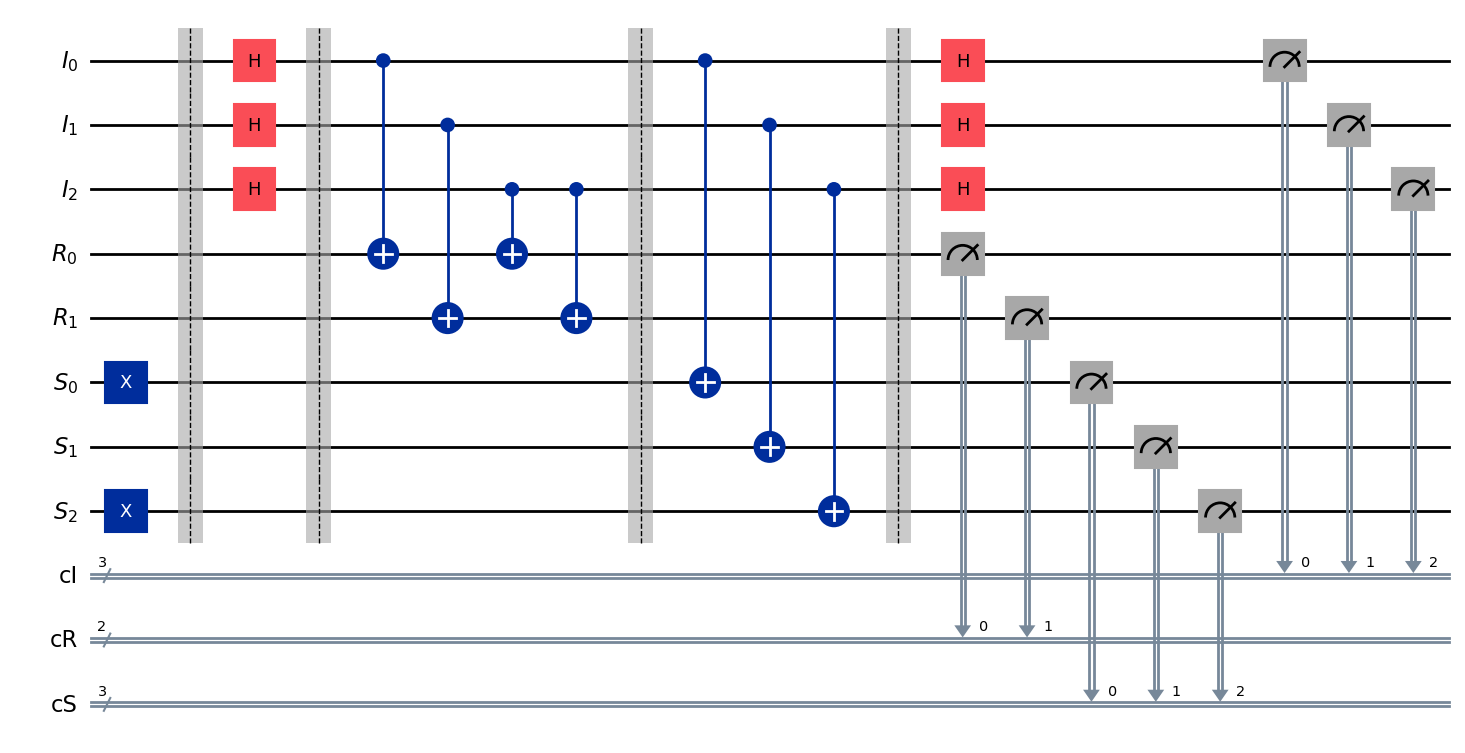


Block 2/2
Key matrix B_2:
[[1 1 1]
 [1 0 0]]


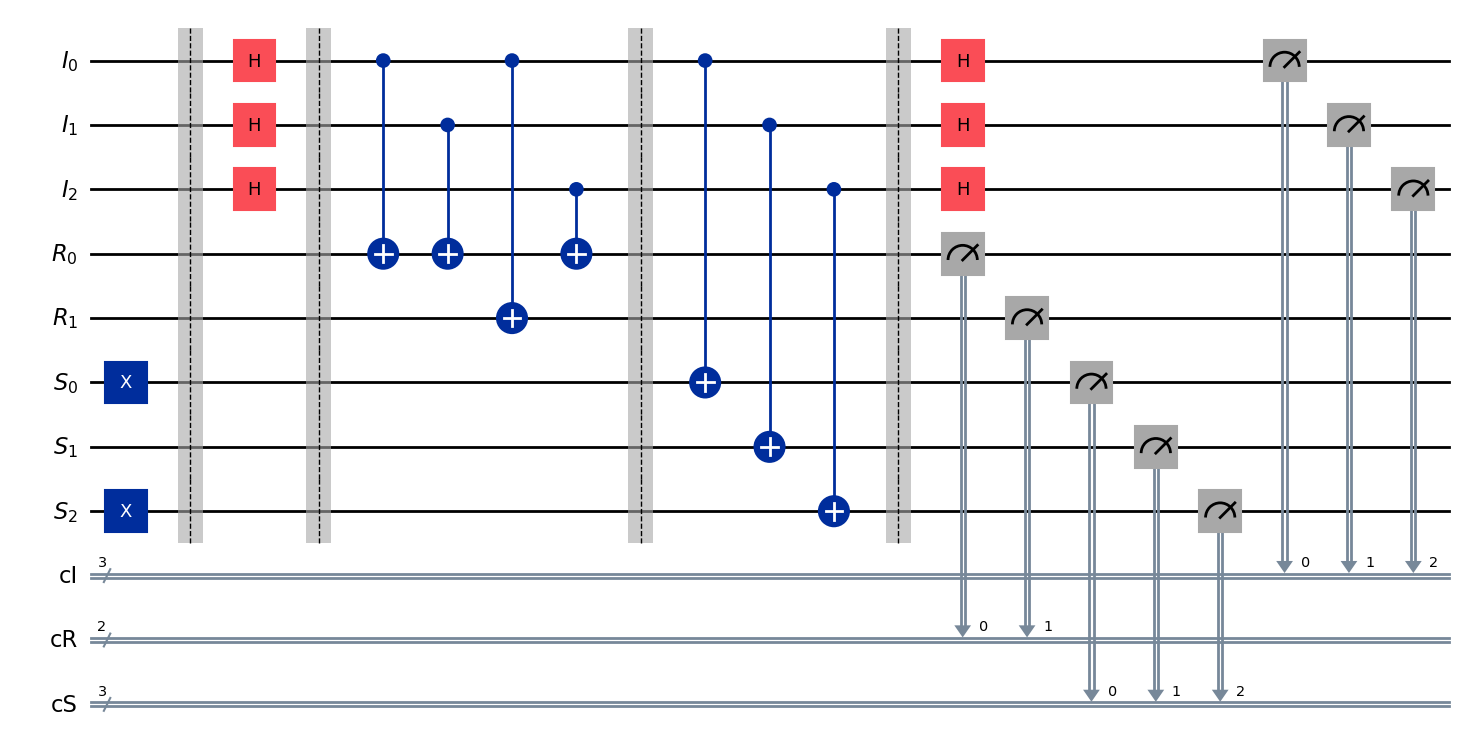

In [4]:
print("XOR permutation family:")
display(model.permutation_table(input_x=X))

for j in range(model.nu):
    print(f"\nBlock {j + 1}/{model.nu}")
    print(f"Key matrix B_{j + 1}:")
    print(model.get_key(j))

    qc = model.circuit(
        x=X,
        block=j,
        measure=True,
        barriers=True,
    )

    display(qc.draw(output="mpl", fold=-1))


## Independent block execution and input reuse

The keyed linear-tag construction consists of multiple
independently keyed circuit executions.

Every block receives a freshly prepared copy of the
same computational-basis input \(x\).

For each block \(j\), the measurement outcomes satisfy

$$
Y_j=x\oplus T_j,
\qquad
R_j=B_jT_j.
$$

The authorized decoder computes

$$
c_j=R_j\oplus B_jY_j=B_jx.
$$

Therefore, all blocks provide linear equations involving
the same unknown input.


In [5]:
# One quantum execution per block, with the SAME original input.
records = model.quantum_sample_all_blocks(
    x=X,
    seed=123,
)

for j, z in enumerate(records):
    B = model.get_key(j)

    # Recover the linear equation contributed by block j.
    c_j = z.r ^ tag_value(B, z.y, model.n)

    # Independently evaluate the expected equation B_j x.
    expected = tag_value(B, X, model.n)

    print(f"\nBlock {j + 1}")
    print(f"Block matrix B_{j + 1}: {model.get_key(j)}")
    print(f"Original input:  {X:0{model.n}b}")
    print(f"System output:   {z.y:0{model.n}b}")
    print(f"Measured tag:    {z.r:0{model.s}b}")
    print(f"Computed B_j x:  {c_j:0{model.s}b}")
    print(f"Expected B_j x:  {expected:0{model.s}b}")

    assert c_j == expected

# Attempt authorized decoding.
recovered = model.decode(records)

print("\nOriginal input:", f"{X:03b}")
print("Recovered input:", f"{recovered:03b}")

if model.resources["full_column_rank"]:
    assert recovered == X
else:
    print("Unique recovery is unavailable: rank(A) < n.")


Block 1
Block matrix B_1: [[1 0 1]
 [0 1 1]]
Original input:  101
System output:   011
Measured tag:    01
Computed B_j x:  10
Expected B_j x:  10

Block 2
Block matrix B_2: [[1 1 1]
 [1 0 0]]
Original input:  101
System output:   001
Measured tag:    01
Computed B_j x:  10
Expected B_j x:  10

Original input: 101
Recovered input: 101


In [7]:
# Usage example of quantum execution and classical sampling 

classical_records = model.sample_all_blocks(
    x=X,
    seed=456,
)

quantum_records = model.quantum_sample_all_blocks(
    x=X,
    seed=789,
)

print(f"Original input: |{X:0{model.n}b}>")

for j, (classical, quantum) in enumerate(
    zip(classical_records, quantum_records)
):
    c = classical.as_bitstrings(
        m=model.m, s=model.s, n=model.n
    )

    q = quantum.as_bitstrings(
        m=model.m, s=model.s, n=model.n
    )

    print(f"\nBlock {j + 1}")
    print(f"Classical: I={c['i']}  R={c['r']}  Y={c['y']}")
    print(f"Quantum:   I={q['i']}  R={q['r']}  Y={q['y']}")

Original input: |101>

Block 1
Classical: I=010  R=10  Y=111
Quantum:   I=001  R=10  Y=111

Block 2
Classical: I=111  R=10  Y=110
Quantum:   I=110  R=01  Y=001


## Proposition 4 - Experiment A


## Proposition 4 — Exact classical transcript sampling

### Objective

We verify that the keyed linear-tag quantum circuit and the
classical sampler produce identical measurement distributions.

For a fixed input $\(x\)$ and secret matrix $\(B_j\)$, the paper
establishes

$$
P(i,r,y\mid x,B_j)
=
2^{-2n}\mathbf{1}_{\{r=B_j(x\oplus y)\}}.
$$

The support of the distribution is therefore

$$
|\operatorname{supp}(P_j)|=2^{2n},
$$

because the index outcome $\(i\)$ and system outcome $\(y\)$
can each assume $\(2^n\)$ values, while the tag $\(r\)$ is
uniquely determined.

We compare three independently obtained distributions:

1. **Theoretical:** probabilities computed from the equation.
2. **Quantum:** probabilities obtained from amplitudes of the State Vector.
3. **Classical:** probabilities obtained by the classical sampling algorithm.

The comparison uses total variation distance:

$$
D_{\mathrm{TV}}(P,Q)
=\frac12\sum_z|P(z)-Q(z)|.
$$

Proposition 4 predicts a distance of zero between all three
distributions in the ideal model.

Note: This experiment does not perform finite-shot sampling.

In [19]:
def total_variation(p: dict, q: dict) -> float:
    """Compute total variation distance between two distributions."""
    outcomes = set(p) | set(q)

    return 0.5 * sum(
        abs(p.get(z, 0.0) - q.get(z, 0.0))
        for z in outcomes
    )


def normalize_counts(counts: dict) -> dict:
    """Convert observed counts into empirical probabilities."""
    total = sum(counts.values())

    if total == 0:
        raise ValueError("Cannot normalize an empty sample.")

    return {
        outcome: count / total
        for outcome, count in counts.items()
    }


def theoretical_distribution(
    model: KeyedLinearTagModel,
    x: int,
    block: int = 0,
) -> dict[Transcript, float]:
    """Evaluate the exact transcript distribution from Eq. (10).

    This implementation uses the analytical formula directly
    and does not call either sampling or simulation method.

    The function requires the paper-exact XOR construction.
    """
    if not model.paper_exact:
        raise ValueError("The paper-exact model is required.")

    B = model.get_key(block)
    probabilities = {}

    for y in range(2**model.n):
        t = x ^ y
        r = tag_value(B, t, model.n)

        for i in range(2**model.n):
            z = Transcript(i=i, r=r, y=y)
            probabilities[z] = 2**(-2 * model.n)

    return probabilities

In [20]:
# ============================================================
# PROPOSITION 4 — EXACT VERIFICATION OF ALL BLOCKS
# ============================================================

TOLERANCE = 1e-12

exact_results = []

# Store each block's distribution for later joint analysis.
theory_by_block = []
quantum_by_block = []
classical_by_block = []

for j in range(model.nu):

    # Compute the exact distributions of block j.
    p_theory = theoretical_distribution(model, X, j)
    p_quantum = model.quantum_probabilities(X, j)
    p_classical = model.classical_probabilities(X, j)

    # Preserve the distributions for subsequent experiments.
    theory_by_block.append(p_theory)
    quantum_by_block.append(p_quantum)
    classical_by_block.append(p_classical)

    # Compare the complete transcript distributions.
    tv_q_theory = total_variation(p_quantum, p_theory)
    tv_c_theory = total_variation(p_classical, p_theory)
    tv_q_c = total_variation(p_quantum, p_classical)

    # A block passes only if all three distances are negligible.
    match = all(
        distance <= TOLERANCE
        for distance in (tv_q_theory, tv_c_theory, tv_q_c)
    )

    exact_results.append({
        "Block": j + 1,
        "Rank(B)": gf2_rank(model.get_key(j)),
        "Support size": len(p_theory),
        "TV(Q, Theory)": tv_q_theory,
        "TV(C, Theory)": tv_c_theory,
        "TV(Q, C)": tv_q_c,
        "Match": match,
    })

# Display the results for all independently keyed blocks.
exact_df = pd.DataFrame(exact_results)

display(exact_df)

# Report success only if every block passes all comparisons.
if exact_df["Match"].all():
    print(
        "SUCCESS: All blocks reproduce the exact "
        "transcript distribution of Proposition 4."
    )
else:
    failed_blocks = exact_df.loc[
        ~exact_df["Match"], "Block"
    ].tolist()

    raise AssertionError(
        f"Proposition 4 verification failed "
        f"for blocks: {failed_blocks}"
    )

,Block,Rank(B),Support size,"TV(Q, Theory)","TV(C, Theory)","TV(Q, C)",Match
0,1,2,64,4.440892e-16,0.0,4.440892e-16,True
1,2,2,64,4.440892e-16,0.0,4.440892e-16,True


SUCCESS: All blocks reproduce the exact transcript distribution of Proposition 4.


The complete construction consists of $\nu$ independently
executed blocks, each using the same original input $x$ and
its corresponding secret matrix $B_j$.

The complete measurement transcript is

$$
\mathbf Z_\nu=(Z_1,\ldots,Z_\nu).
$$

Conditioned on the fixed input and all secret keys, the
individual block transcripts are independent. Therefore,

$$
P(\mathbf Z_\nu\mid x,k)
=
\prod_{j=1}^{\nu}P(Z_j\mid x,B_j).
$$

The single-block equivalence of Proposition 4 consequently
extends to the complete joint transcript distribution:

$$
P_{\mathrm Q}(\mathbf Z_\nu\mid x,k)
=
P_{\mathrm C}(\mathbf Z_\nu\mid x,k).
$$

This is a consequence of Proposition 4 and the independent
block execution model, rather than a separate numbered
proposition in the paper.

The joint distribution has $2^{2n\nu}$ nonzero-probability
outcomes. Explicit enumeration is therefore restricted to
small configurations.

In [21]:
from itertools import product
from math import prod


def joint_distribution(distributions, max_outcomes=20_000):
    """Construct the exact joint distribution of independent blocks.

    Parameters
    ----------
    distributions : list[dict]
        Exact probability distributions of individual blocks.
        Each dictionary maps a Transcript to its probability.
    max_outcomes : int
        Maximum number of joint outcomes to enumerate.

    Returns
    -------
    dict
        Joint probability distribution whose keys are tuples
        of Transcripts, ordered by block.

    Notes
    -----
    The product factorization holds conditional on the fixed
    input x and all fixed secret key matrices.
    """

    # Remove numerically negligible probabilities that may
    # appear in the quantum Statevector calculation.
    distributions = [
        {
            z: float(p)
            for z, p in dist.items()
            if p > 1e-14
        }
        for dist in distributions
    ]

    # Calculate the number of possible joint outcomes.
    support_size = prod(
        len(dist)
        for dist in distributions
    )

    if support_size > max_outcomes:
        raise ValueError(
            f"Joint support contains {support_size:,} outcomes; "
            f"the maximum allowed is {max_outcomes:,}."
        )

    # Enumerate all combinations of individual-block outcomes.
    joint = {}

    for combination in product(
        *(dist.items() for dist in distributions)
    ):

        # The complete transcript is (Z_1, ..., Z_nu).
        records = tuple(
            outcome
            for outcome, _ in combination
        )

        # Independence gives the product of probabilities.
        probability = prod(
            p
            for _, p in combination
        )

        joint[records] = probability

    return joint

In [22]:
JOINT_LIMIT = 20_000
TOLERANCE = 1e-12

joint_support_size = 2 ** (2 * model.n * model.nu)

print(f"Original input: |{X:0{model.n}b}>")
print(f"Number of blocks: {model.nu}")
print(f"Support per block: {2 ** (2 * model.n):,}")
print(f"Complete transcript support: {joint_support_size:,}")

# Set to None if exact joint enumeration is not feasible.
p_joint_theory = None
p_joint_quantum = None
p_joint_classical = None

if joint_support_size <= JOINT_LIMIT:

    # Construct exact joint distributions.
    p_joint_theory = joint_distribution(
        theory_by_block,
        max_outcomes=JOINT_LIMIT,
    )

    p_joint_quantum = joint_distribution(
        quantum_by_block,
        max_outcomes=JOINT_LIMIT,
    )

    p_joint_classical = joint_distribution(
        classical_by_block,
        max_outcomes=JOINT_LIMIT,
    )

    # Compare the three complete probability distributions.
    joint_results = {
        "Quantum vs theoretical": total_variation(
            p_joint_quantum,
            p_joint_theory,
        ),
        "Classical vs theoretical": total_variation(
            p_joint_classical,
            p_joint_theory,
        ),
        "Quantum vs classical": total_variation(
            p_joint_quantum,
            p_joint_classical,
        ),
    }

    display(
        pd.DataFrame(
            joint_results.items(),
            columns=["Comparison", "TV distance"],
        )
    )

    # Validate the normalization of each joint distribution.
    for p in (
        p_joint_theory,
        p_joint_quantum,
        p_joint_classical,
    ):
        assert np.isclose(
            sum(p.values()),
            1.0,
            atol=TOLERANCE,
        )

    # Print success only if every comparison actually passes.
    if all(
        distance <= TOLERANCE
        for distance in joint_results.values()
    ):
        print(
            "SUCCESS: All exact joint transcript "
            "distributions match."
        )
    else:
        raise AssertionError(
            "Proposition 4: joint distribution mismatch."
        )

else:
    print(
        "SKIPPED: Explicit joint distribution enumeration "
        "exceeds the configured limit."
    )
    print(
        "Joint equivalence follows from the per-block "
        "equalities and conditional independence, "
        "but was not enumerated numerically."
    )

Original input: |101>
Number of blocks: 2
Support per block: 64
Complete transcript support: 4,096


,Comparison,TV distance
0,Quantum vs theoretical,8.881784e-16
1,Classical vs theoretical,0.000000e+00
2,Quantum vs classical,8.881784e-16


SUCCESS: All exact joint transcript distributions match.



### Finite-shot quantum and classical sampling

After verifying the exact distribution identity of Proposition 4,
we investigate its behavior under finite-shot sampling.

We compare two sampling procedures:

- **Quantum sampling:** execution of the keyed quantum circuit
  using the Qiskit Aer simulator.
- **Classical sampling:** execution of the efficient classical
  algorithm established by Proposition 4.

Both procedures use the same original input $x$ and the same
fixed key matrix $B_j$ for each block.

Given $N$ measurement shots, empirical probabilities are
estimated by relative frequencies:

$$
\widehat P_j(z)
=
\frac{N_j(z)}{N}.
$$

We quantify their agreement through total variation distance:

$$
D_{\mathrm{TV}}(P,Q)
=
\frac{1}{2}\sum_z |P(z)-Q(z)|.
$$

Unlike exact probability comparisons, finite-shot distances
are generally nonzero due to statistical sampling fluctuations.

Repeated shots with fixed keys are used only to estimate the
distributions, not to test the fresh-key inversion-security
experiment.


In [28]:
# ============================================================
# PROPOSITION 4 — FINITE-SHOT VERIFICATION FOR ALL BLOCKS
# ============================================================

SHOTS = 50000

sampling_results = []
sampling_by_block = {}

for j in range(model.nu):

    # The exact theoretical distribution of block j.
    p_theory = theory_by_block[j]

    # Quantum circuit sampling using Qiskit Aer.
    q_counts = model.quantum_counts(
        x=X,
        block=j,
        shots=SHOTS,
        seed=1000 + j,
    )

    # Efficient classical sampling from Proposition 4.
    c_counts = model.classical_counts(
        x=X,
        block=j,
        shots=SHOTS,
        seed=2000 + j,
    )

    # Check the number of generated measurement outcomes.
    assert sum(q_counts.values()) == SHOTS
    assert sum(c_counts.values()) == SHOTS

    # Check that all sampled outcomes satisfy the theoretical support.
    assert set(q_counts).issubset(p_theory)
    assert set(c_counts).issubset(p_theory)

    # Convert measurement counts to empirical probabilities.
    p_q = normalize_counts(q_counts)
    p_c = normalize_counts(c_counts)

    # Compute empirical total variation distances.
    tv_q_theory = total_variation(p_q, p_theory)
    tv_c_theory = total_variation(p_c, p_theory)
    tv_q_c = total_variation(p_q, p_c)

    sampling_results.append({
        "Block": j + 1,
        "Shots": SHOTS,
        "TV(Q, Theory)": tv_q_theory,
        "TV(C, Theory)": tv_c_theory,
        "TV(Q, C)": tv_q_c,
    })

    # Save data for subsequent visualizations.
    sampling_by_block[j] = {
        "theory": p_theory,
        "quantum": p_q,
        "classical": p_c,
    }

# Display individual-block results.
sampling_df = pd.DataFrame(sampling_results)

display(sampling_df)

print(f"Input: |{X:0{model.n}b}>")
print(f"Number of blocks: {model.nu}")
print(f"Shots per block: {SHOTS:,}")
print(f"Total circuit executions: {model.nu * SHOTS:,}")
print("All sampled outcomes satisfy the theoretical support.")

,Block,Shots,"TV(Q, Theory)","TV(C, Theory)","TV(Q, C)"
0,1,50000,0.012120,0.013840,0.01910
1,2,50000,0.014005,0.013565,0.01976


Input: |101>
Number of blocks: 2
Shots per block: 50,000
Total circuit executions: 100,000
All sampled outcomes satisfy the theoretical support.


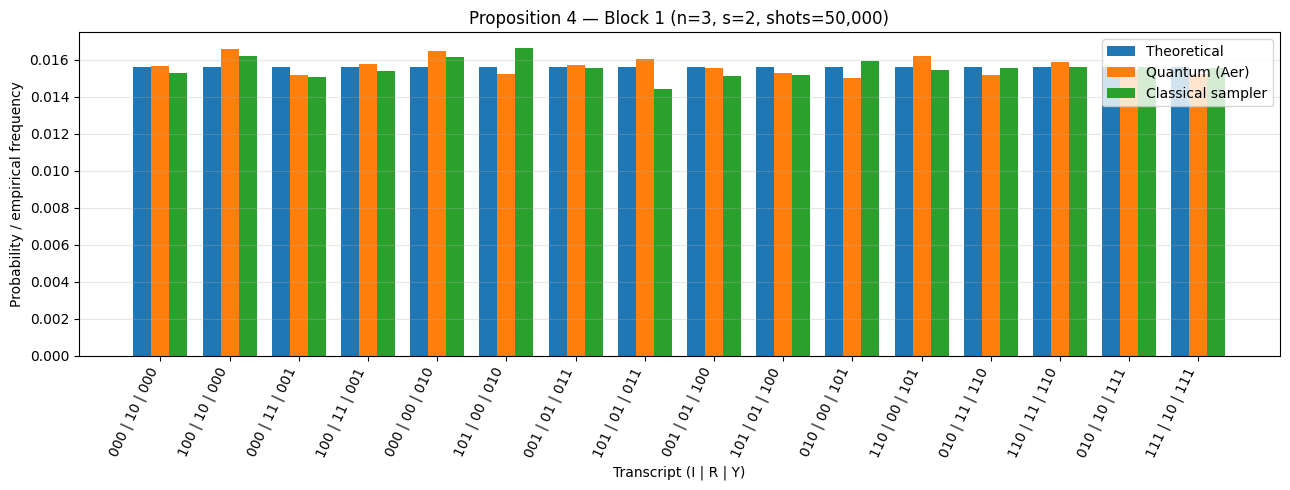

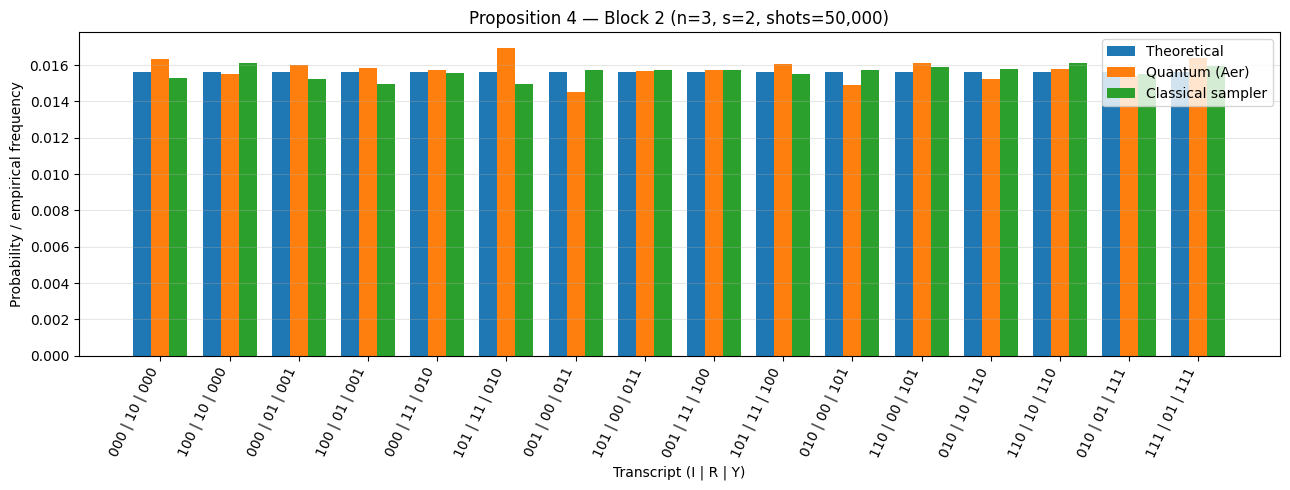

In [30]:
# ============================================================
# PROPOSITION 4 — VISUALIZE MEASUREMENT DISTRIBUTIONS
# ============================================================

MAX_DISPLAY_OUTCOMES = 16

for j in range(model.nu):

    # Retrieve the distributions of the current block.
    distributions = sampling_by_block[j]

    p_theory = distributions["theory"]
    p_quantum = distributions["quantum"]
    p_classical = distributions["classical"]

    # Sort all theoretically valid measurement outcomes.
    outcomes = sorted(
        p_theory,
        key=lambda z: (z.y, z.i, z.r),
    )

    # Select evenly spaced outcomes for a readable plot.
    num_display = min(MAX_DISPLAY_OUTCOMES, len(outcomes))

    indices = np.linspace(
        0,
        len(outcomes) - 1,
        num=num_display,
        dtype=int,
    )

    selected = [outcomes[k] for k in indices]

    # Represent all registers as computational-basis bitstrings.
    labels = [
        (
            f"{z.i:0{model.m}b} | "
            f"{z.r:0{model.s}b} | "
            f"{z.y:0{model.n}b}"
        )
        for z in selected
    ]

    # Extract theoretical and empirical probabilities.
    theoretical_values = [
        p_theory[z]
        for z in selected
    ]

    quantum_values = [
        p_quantum.get(z, 0.0)
        for z in selected
    ]

    classical_values = [
        p_classical.get(z, 0.0)
        for z in selected
    ]

    # Create the grouped bar chart.
    positions = np.arange(len(selected))
    bar_width = 0.26

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.bar(
        positions - bar_width,
        theoretical_values,
        width=bar_width,
        label="Theoretical",
    )

    ax.bar(
        positions,
        quantum_values,
        width=bar_width,
        label="Quantum (Aer)",
    )

    ax.bar(
        positions + bar_width,
        classical_values,
        width=bar_width,
        label="Classical sampler",
    )

    # Format axes and labels.
    ax.set_xticks(positions)
    ax.set_xticklabels(
        labels,
        rotation=65,
        ha="right",
    )

    ax.set_xlabel("Transcript (I | R | Y)")
    ax.set_ylabel("Probability / empirical frequency")

    ax.set_title(
        f"Proposition 4 — Block {j + 1} "
        f"(n={model.n}, s={model.s}, shots={SHOTS:,})"
    )

    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

In [31]:
# ============================================================
# PROPOSITION 4 — SAMPLING CONVERGENCE
# ============================================================

SHOT_VALUES = [256, 512, 1024, 2048, 4096, 8192, 16384]

convergence_results = []

for shots in SHOT_VALUES:
    for j in range(model.nu):

        # Exact theoretical distribution for block j.
        p_theory = theory_by_block[j]

        # Quantum circuit simulation using Qiskit Aer.
        q_counts = model.quantum_counts(
            x=X,
            block=j,
            shots=shots,
            seed=10000 + 100 * j + shots,
        )

        # Classical sampler from Proposition 4.
        c_counts = model.classical_counts(
            x=X,
            block=j,
            shots=shots,
            seed=20000 + 100 * j + shots,
        )

        assert sum(q_counts.values()) == shots
        assert sum(c_counts.values()) == shots
        assert set(q_counts).issubset(p_theory)
        assert set(c_counts).issubset(p_theory)

        p_q = normalize_counts(q_counts)
        p_c = normalize_counts(c_counts)

        convergence_results.append({
            "Shots": shots,
            "Block": j + 1,
            "TV(Q, Theory)": total_variation(p_q, p_theory),
            "TV(C, Theory)": total_variation(p_c, p_theory),
            "TV(Q, C)": total_variation(p_q, p_c),
        })

convergence_df = pd.DataFrame(convergence_results)

display(convergence_df)

,Shots,Block,"TV(Q, Theory)","TV(C, Theory)","TV(Q, C)"
0,256,1,0.195312,0.164062,0.277344
1,256,2,0.179688,0.179688,0.269531
2,512,1,0.138672,0.144531,0.197266
3,512,2,0.136719,0.125000,0.183594
4,1024,1,0.100586,0.111328,0.138672
5,1024,2,0.107422,0.099609,0.159180
6,2048,1,0.069336,0.068359,0.098633
7,2048,2,0.060059,0.066406,0.082031
8,4096,1,0.047607,0.049316,0.065918
9,4096,2,0.050781,0.055176,0.081543


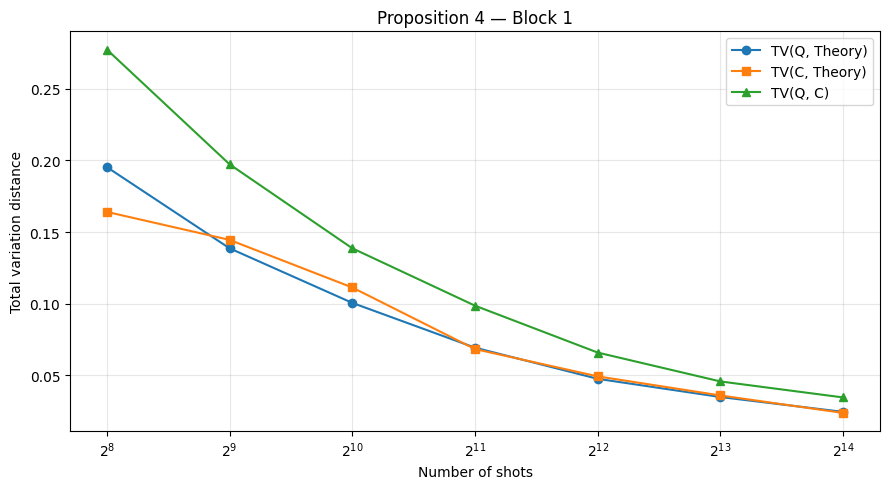

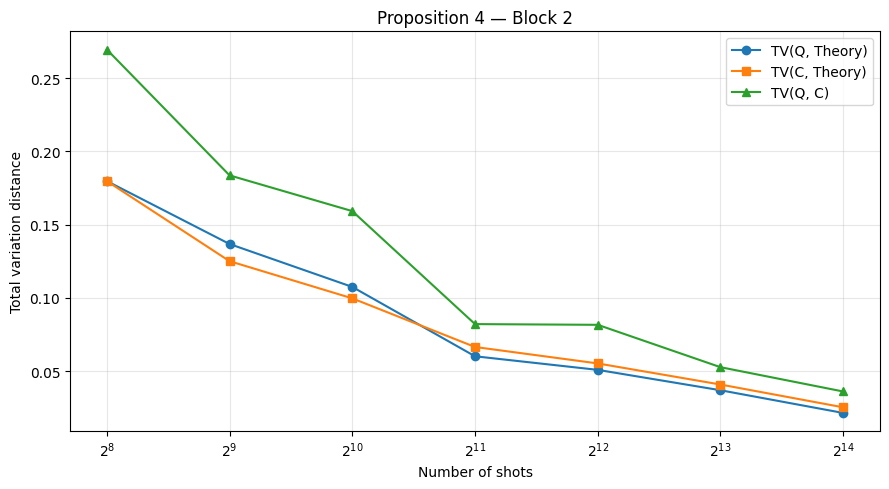

In [32]:
# ============================================================
# PROPOSITION 4 — PER-BLOCK CONVERGENCE
# ============================================================

for j in range(model.nu):

    block_df = convergence_df[
        convergence_df["Block"] == j + 1
    ].sort_values("Shots")

    fig, ax = plt.subplots(figsize=(9, 5))

    for column, marker in [
        ("TV(Q, Theory)", "o"),
        ("TV(C, Theory)", "s"),
        ("TV(Q, C)", "^"),
    ]:
        ax.plot(
            block_df["Shots"],
            block_df[column],
            marker=marker,
            label=column,
        )

    ax.set_xscale("log", base=2)
    ax.set_xlabel("Number of shots")
    ax.set_ylabel("Total variation distance")
    ax.set_title(f"Proposition 4 — Block {j + 1}")

    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()


## Proposition 5 — Authorized decoding

We now investigate the authorized decoding procedure described
in Section IV of the paper.

For every independently keyed block $j$, the measurement
transcript is

$$
Z_j=(I_j,R_j,Y_j).
$$

The authorized decoder knows the secret matrix $B_j$ and
computes

$$
c_j=R_j\oplus B_jY_j.
$$

From the linear-tag measurement relation,

$$
R_j=B_j(x\oplus Y_j),
$$

we obtain

$$
c_j=B_j(x\oplus Y_j)\oplus B_jY_j=B_jx.
$$

Combining all $\nu$ blocks gives the binary linear system

$$
A=
\begin{pmatrix}
B_1\\
B_2\\
\vdots\\
B_\nu
\end{pmatrix},
\qquad
c=
\begin{pmatrix}
c_1\\
c_2\\
\vdots\\
c_\nu
\end{pmatrix},
\qquad
Ax=c.
$$

Here $A$ is a $(\nu s)\times n$ binary matrix.

**Proposition 5** states that if

$$
\operatorname{rank}_{\mathbb F_2}(A)=n,
$$

the authorized decoder recovers the original input $x$
with probability one in the ideal circuit model.

The decoder solves $Ax=c$ using Gaussian elimination over
$\mathbb F_2$, without requiring the explicit construction
of a left inverse.

If $A$ is rank deficient, the decoder reports failure.


In [34]:
# One classical execution of each independently keyed block.
classical_records = model.sample_all_blocks(X)

# One quantum circuit execution per block, always using X.
quantum_records = [
    next(iter(model.quantum_counts(
        x=X,
        block=j,
        shots=1,
        seed=5000 + j,
    )))
    for j in range(model.nu)
]

# Vertically stack all secret matrices.
A = np.vstack([
    model.get_key(j)
    for j in range(model.nu)
])

rank_A = gf2_rank(A)
full_rank = rank_A == model.n

print(f"Original input: |{X:0{model.n}b}>")
print(f"Stacked matrix A:\n{A}")
print(f"Rank(A): {rank_A} / {model.n}")

results = []

for method, records in [
    ("Classical", classical_records),
    ("Quantum", quantum_records),
]:

    for j, z in enumerate(records):
        B = model.get_key(j)

        # Reconstruct the deterministic linear syndrome.
        c_j = z.r ^ tag_value(B, z.y, model.n)

        # Verify the paper's relation c_j = B_j x.
        expected = tag_value(B, X, model.n)
        assert c_j == expected

        results.append({
            "Method": method,
            "Block": j + 1,
            "I": f"{z.i:0{model.n}b}",
            "R": f"{z.r:0{model.s}b}",
            "Y": f"{z.y:0{model.n}b}",
            "c_j": f"{c_j:0{model.s}b}",
        })

    # Decode the complete collection of block transcripts.
    recovered = model.decode(records)

    if full_rank:
        assert recovered == X
        print(
            f"{method}: SUCCESS — recovered "
            f"|{recovered:0{model.n}b}>"
        )
    else:
        assert recovered is None
        print(
            f"{method}: decoding failure — "
            "A does not have full column rank."
        )

display(pd.DataFrame(results))

Original input: |101>
Stacked matrix A:
[[1 0 1]
 [0 1 1]
 [1 1 1]
 [1 0 0]]
Rank(A): 3 / 3
Classical: SUCCESS — recovered |101>
Quantum: SUCCESS — recovered |101>


,Method,Block,I,R,Y,c_j
0,Classical,1,101,11,001,10
1,Classical,2,110,10,110,10
2,Quantum,1,001,10,000,10
3,Quantum,2,111,01,111,10


In [35]:
input_results = []

for x in range(2**model.n):

    # Fresh classical transcript, same x for every block.
    records = model.sample_all_blocks(x)

    recovered = model.decode(records)

    passed = (
        recovered == x
        if full_rank
        else recovered is None
    )

    input_results.append({
        "Input": f"{x:0{model.n}b}",
        "Recovered": (
            f"{recovered:0{model.n}b}"
            if recovered is not None
            else "Failure"
        ),
        "Pass": passed,
    })

input_df = pd.DataFrame(input_results)

display(input_df)

if input_df["Pass"].all():
    print(
        "SUCCESS: Authorized decoding behaves as predicted "
        "for all computational-basis inputs."
    )
else:
    raise AssertionError("Authorized decoding verification failed.")

,Input,Recovered,Pass
0,000,000,True
1,001,001,True
2,010,010,True
3,011,011,True
4,100,100,True
5,101,101,True
6,110,110,True
7,111,111,True


SUCCESS: Authorized decoding behaves as predicted for all computational-basis inputs.



## Corollary 1 — Random-key decoding failure

Proposition 5 guarantees exact authorized recovery whenever
the stacked key matrix $A$ has full column rank.

Corollary 1 studies the probability that this condition fails
when the block keys are sampled independently and uniformly.

Let

$$
A\in\mathbb F_2^{\nu s\times n}.
$$

The ideal decoding failure probability is

$$
\epsilon_{\mathrm{corr}}(n,\nu)
=
\Pr[\operatorname{rank}_{\mathbb F_2}(A)<n].
$$

Corollary 1 establishes the upper bound

$$
\epsilon_{\mathrm{corr}}(n,\nu)
\le
\frac{2^n-1}{2^{\nu s}}
<
2^{n-\nu s}.
$$

We estimate this failure probability empirically by
generating many independent random key sets and checking
the rank of each stacked matrix.

For comparison, the exact rank-deficiency probability of
a uniformly random binary matrix with $r=\nu s$ rows and
$n$ columns is

$$
\epsilon_{\mathrm{exact}}(n,r)
=
\begin{cases}
1, & r<n,\\
1-\displaystyle\prod_{i=0}^{n-1}(1-2^{i-r}), & r\ge n.
\end{cases}
$$

The exact formula provides an additional analytical
reference. The bound stated in the paper is the simpler
union bound from Corollary 1.

A failure in this experiment is caused by insufficient
matrix rank, not by measurement randomness or simulator
noise.


In [38]:
from math import prod

RANK_N = 8
RANK_S = 2
NU_VALUES = range(2, 9)
TRIALS = 3000

rng = np.random.default_rng(2027)


def exact_failure_probability(n, rows):
    """Exact rank-deficiency probability over GF(2)."""
    if rows < n:
        return 1.0

    return 1.0 - prod(
        1.0 - 2.0**(i - rows)
        for i in range(n)
    )


failure_results = []

for nu in NU_VALUES:

    rows = nu * RANK_S
    failures = 0

    for _ in range(TRIALS):

        # Fresh independent uniform binary key matrices.
        # Stacking nu matrices of shape (s, n) gives A.
        A = rng.integers(
            0, 2,
            size=(rows, RANK_N),
            dtype=np.uint8,
        )

        # Under the ideal decoder, failure occurs exactly
        # when A does not have full column rank.
        if gf2_rank(A) < RANK_N:
            failures += 1

    empirical = failures / TRIALS

    exact = exact_failure_probability(RANK_N, rows)

    # Cap the union bound at 1 for probability plots.
    corollary_bound = min(
        1.0,
        (2**RANK_N - 1) / 2**rows,
    )

    failure_results.append({
        "nu": nu,
        "nu*s": rows,
        "Failures": failures,
        "Trials": TRIALS,
        "Empirical failure": empirical,
        "Exact probability": exact,
        "Corollary 1 bound": corollary_bound,
    })

failure_df = pd.DataFrame(failure_results)

display(failure_df)

,nu,nu*s,Failures,Trials,Empirical failure,Exact probability,Corollary 1 bound
0,2,6,3000,3000,1.000000,1.000000,1.000000
1,3,9,1264,3000,0.421333,0.421294,0.498047
2,4,12,156,3000,0.052000,0.060980,0.062256
3,5,15,26,3000,0.008667,0.007762,0.007782
4,6,18,2,3000,0.000667,0.000972,0.000973
5,7,21,1,3000,0.000333,0.000122,0.000122
6,8,24,0,3000,0.000000,0.000015,0.000015


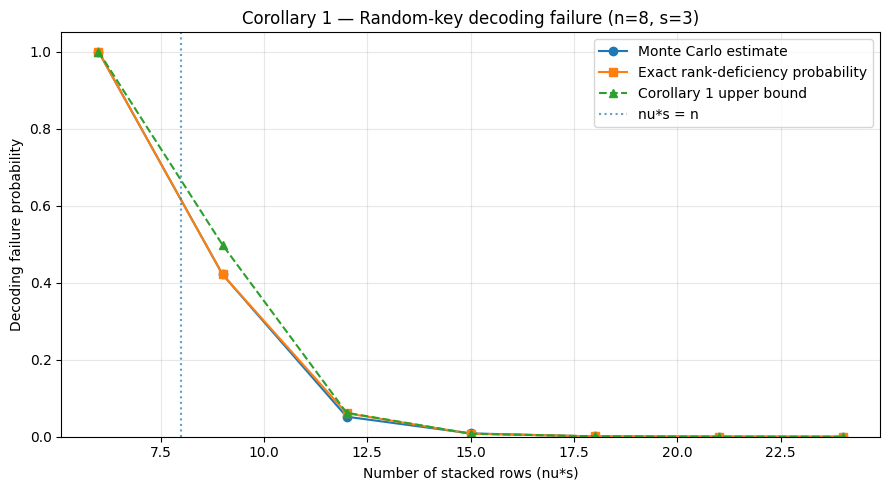

In [39]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    failure_df["nu*s"],
    failure_df["Empirical failure"],
    marker="o",
    label="Monte Carlo estimate",
)

ax.plot(
    failure_df["nu*s"],
    failure_df["Exact probability"],
    marker="s",
    label="Exact rank-deficiency probability",
)

ax.plot(
    failure_df["nu*s"],
    failure_df["Corollary 1 bound"],
    linestyle="--",
    marker="^",
    label="Corollary 1 upper bound",
)

ax.axvline(
    RANK_N,
    linestyle=":",
    alpha=0.7,
    label="nu*s = n",
)

ax.set_xlabel("Number of stacked rows (nu*s)")
ax.set_ylabel("Decoding failure probability")

ax.set_title(
    f"Corollary 1 — Random-key decoding failure "
    f"(n={RANK_N}, s={RANK_S})"
)

ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


### Interpretation of Corollary 1

The Monte Carlo experiment estimates the ideal authorized
decoding failure probability over independently generated
uniform binary keys.

The empirical failure rate is compared with the exact
rank-deficiency probability and the upper bound established
by Corollary 1.

When $\nu s<n$, full column rank is impossible and the
decoder necessarily reports failure.

As $\nu s$ increases beyond $n$, the probability of
rank deficiency decreases, confirming the reliability
improvement predicted by the paper.

For a target margin $\Delta\ge 0$, choosing

$$
\nu=\left\lceil\frac{n+\Delta}{s}\right\rceil
$$

ensures

$$
\nu s\ge n+\Delta,
\qquad
\epsilon_{\mathrm{corr}}(n,\nu)<2^{-\Delta}.
$$

Importantly, this probability is taken over random key
generation. For a single fixed key set, ideal decoding
either succeeds for every valid transcript when $A$ has
full column rank, or reports failure when it does not.

The experiment concerns correctness, not adversarial
inversion security.
